# Load and Inspect the Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

images_dir = Path("../images")
images_dir.mkdir(parents=True, exist_ok=True)

In [3]:
df = pd.read_csv("../data/ai4i2020.csv")
print("Dataset shape:", df.shape)
display(df.head())
df.info()
display(df.describe())

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [4]:
# Check missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

Missing values per column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

Number of duplicate rows:
0

Data types:
UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object


# Exploratory Data Analysis (EDA)

In [5]:
failure_counts = df["Machine failure"].value_counts()

failure_percentages = df["Machine failure"].value_counts(normalize=True) * 100

print("Counts:")
print(failure_counts)

print("\nPercentages:")
print(failure_percentages.round(2))

Counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


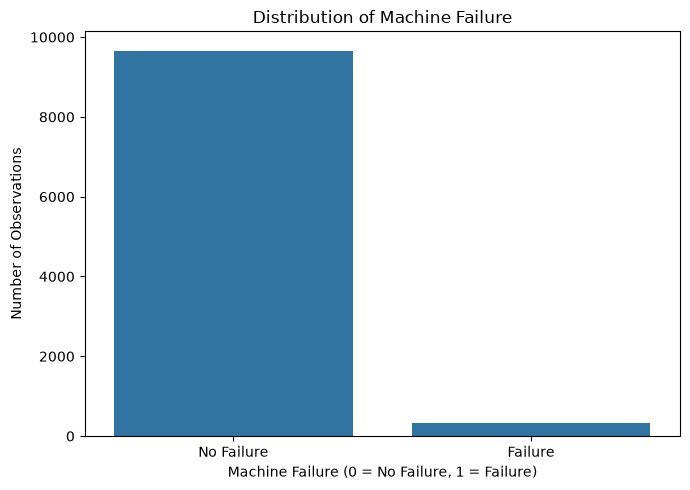

In [6]:
failure_counts = (
    df["Machine failure"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=failure_counts.index,
    y=failure_counts.values
)

plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Observations")
plt.xticks([0, 1], ["No Failure", "Failure"])

plt.tight_layout()
plt.savefig(images_dir / "01_failure_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
df.columns.tolist()

['UDI',
 'Product ID',
 'Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

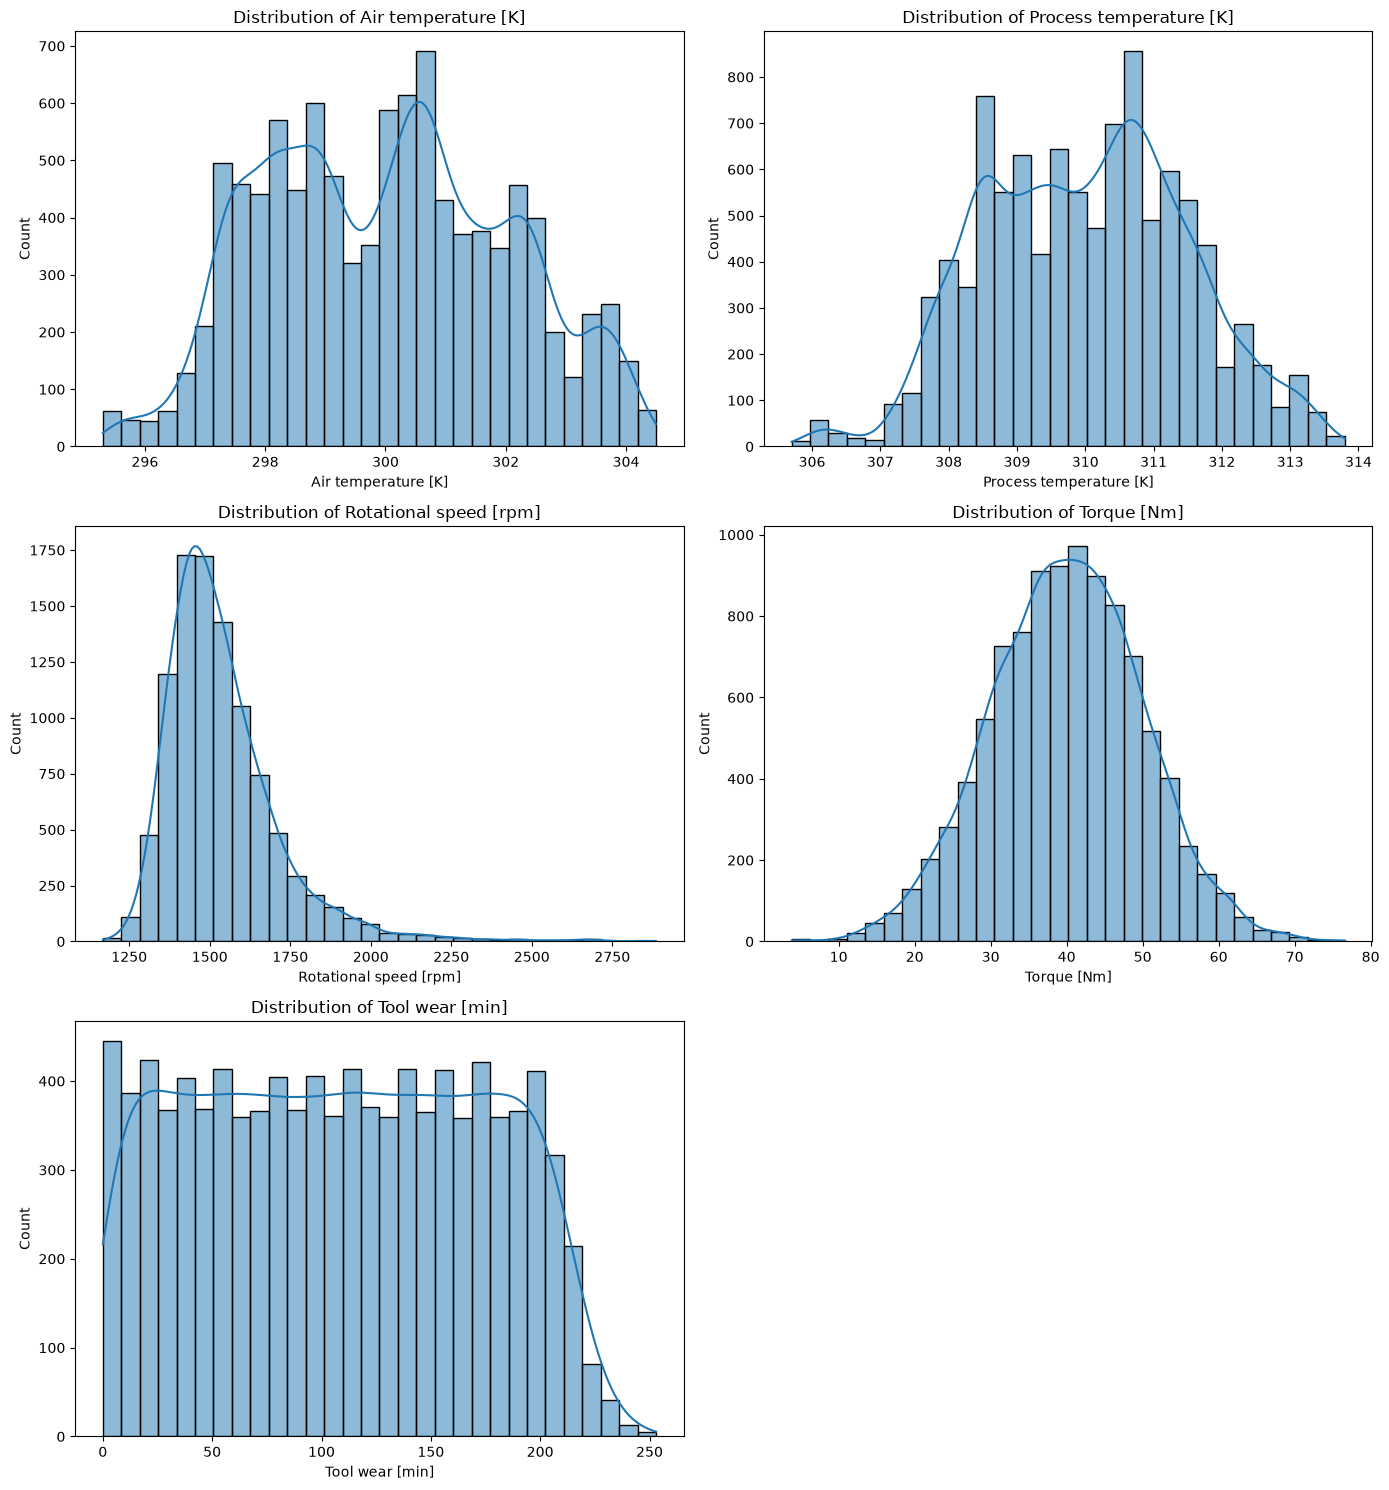

In [8]:
sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

axes = axes.flatten()

for i, feature in enumerate(sensor_features):
    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {feature}")

axes[-1].set_visible(False)

plt.tight_layout()
plt.savefig(images_dir / "02_sensor_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

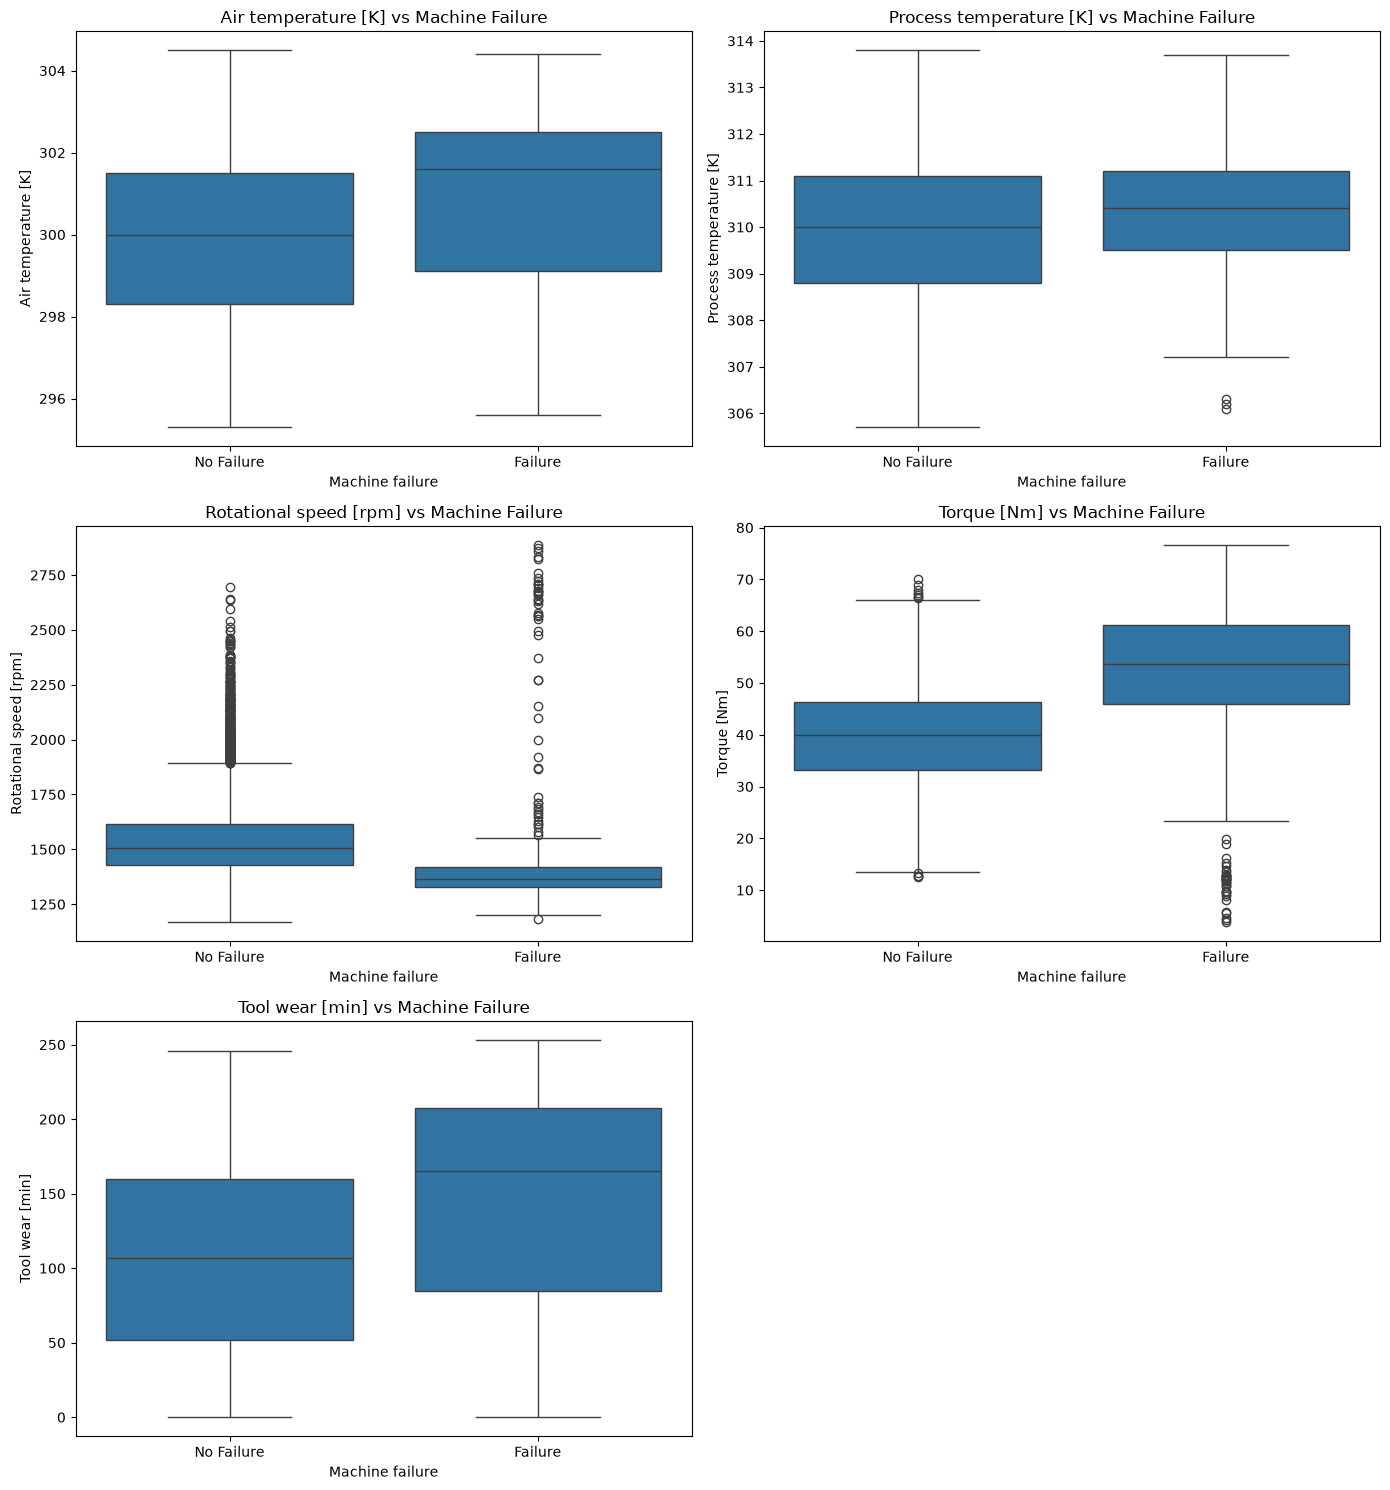

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

axes = axes.flatten()

for i, feature in enumerate(sensor_features):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs Machine Failure")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["No Failure", "Failure"])

axes[-1].set_visible(False)

plt.tight_layout()
plt.savefig(images_dir / "03_sensors_vs_failure.png", dpi=300, bbox_inches="tight")
plt.show()

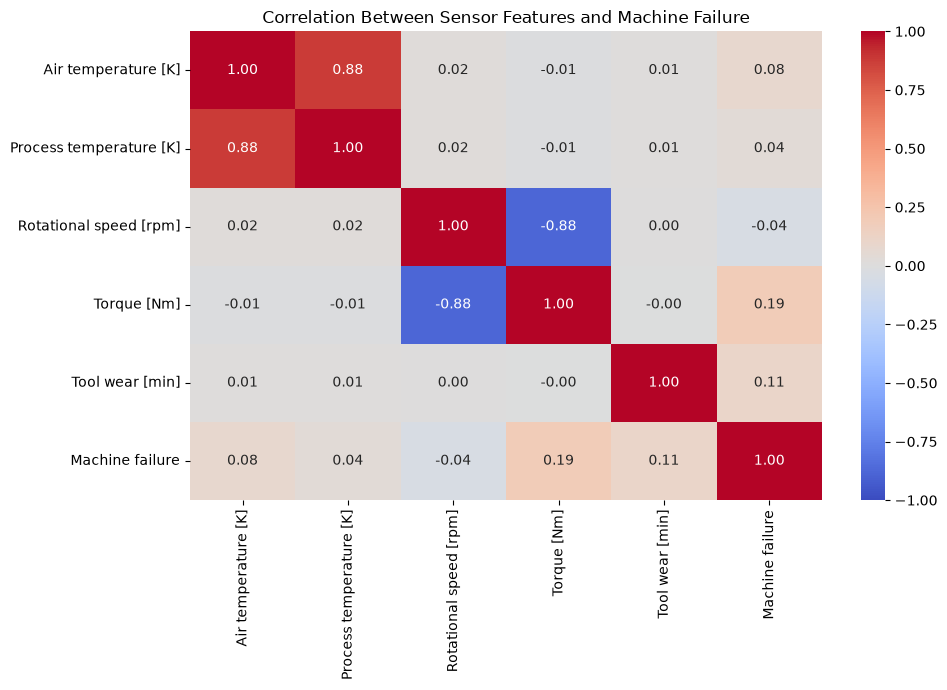

In [10]:
sensor_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

correlation_columns = sensor_features + ["Machine failure"]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Sensor Features and Machine Failure")
plt.tight_layout()
plt.savefig(images_dir / "04_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
failure_by_type = (
    df.groupby("Type")["Machine failure"]
    .agg(["sum", "count", "mean"])
)

failure_by_type["failure_rate_percent"] = (
    failure_by_type["mean"] * 100
)

failure_by_type = failure_by_type.drop(columns="mean")

display(failure_by_type)

,sum,count,failure_rate_percent
Type,,,
H,21,1003,2.093719
L,235,6000,3.916667
M,83,2997,2.769436


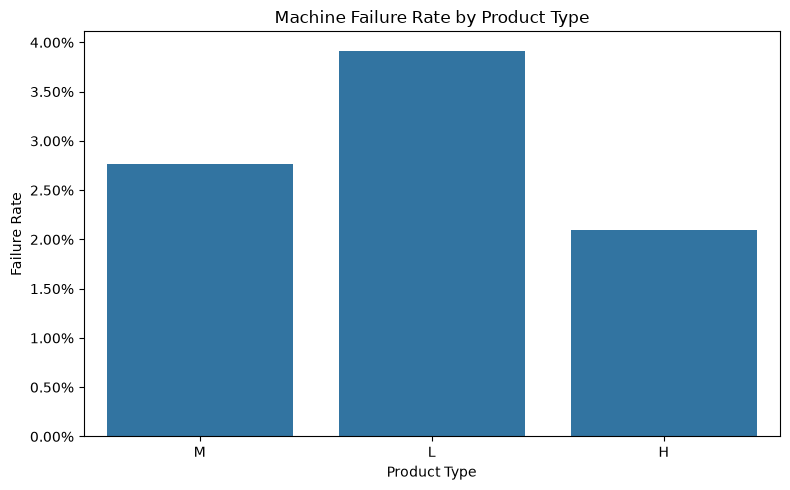

In [12]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Type",
    y="Machine failure",
    errorbar=None
)

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate")
plt.gca().yaxis.set_major_formatter(
    plt.matplotlib.ticker.PercentFormatter(1)
)

plt.tight_layout()
plt.savefig( images_dir / "05_failure_rate_by_product_type.png", dpi=300, bbox_inches="tight" )
plt.show()

## EDA Findings

### 1. Target Distribution
- Number of normal observations: 9661
- Number of failure observations: 339
- Percentage of failures: 3.39%
- Is the target imbalanced? 
The dataset is highly imbalanced, with 96.61% of observations representing normal machine operation and only 3.39% representing machine failures. This imbalance may cause a model to favor the majority class and perform poorly when identifying actual failures. Therefore, accuracy alone is not a sufficient evaluation metric, and metrics such as precision, recall, and F1-score should also be considered.


### 2. Sensor Distributions

- **Air temperature:** The values range from approximately 295.5 K to 304.5 K, with most observations falling between 297 K and 303 K. The distribution is multimodal, with several visible peaks.

- **Process temperature:** The values range from approximately 305.5 K to 314 K, with most observations concentrated between 308 K and 312 K. The distribution shows multiple peaks rather than a single, symmetric bell shape.

- **Rotational speed:** Most observations fall between approximately 1,350 and 1,750 rpm. The distribution is right-skewed, with a long tail toward higher speeds and a few extreme values.

- **Torque:** Most values are concentrated between approximately 25 and 55 Nm, with a peak around 40 Nm. The distribution is approximately symmetric and bell-shaped.

- **Tool wear:** The values range from 0 to approximately 250 minutes. The distribution is relatively uniform across much of the range, followed by a sharp decline above 200 minutes.

These plots help us understand the typical operating conditions of the machines and identify potential unusual values. However, they do not show whether a sensor is associated with machine failure; this will be investigated by comparing sensor readings between normal and failed machines.

### 3. Sensors vs Machine Failure

Comparing sensor readings between normal and failed machines reveals several visible differences:

- **Air temperature:** Machines that experienced failure generally show a higher median air temperature than machines without failure. However, the two distributions overlap considerably.

- **Process temperature:** The median process temperature is slightly higher for failed machines, but the distributions overlap substantially, suggesting that this feature alone may not clearly distinguish between the two groups.

- **Rotational speed:** Failed machines generally have a lower median rotational speed than normal machines. However, the failure group contains several extreme values, and some overlap exists between the distributions.

- **Torque:** Failed machines show a noticeably higher median torque than normal machines. Although the medians differ, the distributions still overlap.

- **Tool wear:** Failed machines generally have higher tool wear values, with a noticeably higher median than normal machines. However, the distributions overlap, meaning that high tool wear does not always indicate machine failure.

**Limitations:**

These boxplots reveal differences in the distributions but do not establish causation or prove that any individual feature causes machine failure. Overlapping distributions indicate that no single feature perfectly separates the two groups. Furthermore, machine failure is relatively rare in this dataset, so these visual comparisons should be complemented by appropriate statistical analysis and model evaluation.

### 4. Machine Failure Rate by Product Type

The failure rate varies across product types:

* **Type L:** Has the highest failure rate, at approximately 3.9%.
* **Type M:** Has a failure rate of approximately 2.75%.
* **Type H:** Has the lowest failure rate, at approximately 2.1%.

These differences suggest that product type may provide useful information for predicting machine failure. However, the observed differences do not establish that product type causes machine failure. Further analysis and model evaluation are needed to determine its predictive value.

### 5. Why Accuracy Can Be Misleading

Accuracy can be misleading when working with imbalanced datasets, where one class is much more common than the other.

In this dataset, 9,661 out of 10,000 observations represent normal machine operation, while only 339 represent machine failure.

A model that always predicts "No Failure" would achieve an accuracy of **96.61%**, despite failing to identify any actual machine failures.

Therefore, accuracy alone is not sufficient to evaluate model performance. Other metrics should also be considered:

- **Precision:** Measures how many predicted failures are actually failures.
- **Recall:** Measures how many actual failures the model successfully identifies.
- **F1-score:** Balances precision and recall.
- **Confusion matrix:** Shows correct and incorrect predictions for both classes.

For predictive maintenance, recall is particularly important because failing to detect an actual machine failure could lead to unexpected downtime and costly repairs. However, precision must also be considered to avoid excessive false alarms.

# Prepare the Features and Target

In [13]:
target = "Machine failure"

feature_columns = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[feature_columns].copy()
y = df[target].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (10000, 6)
Target shape: (10000,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


0    0
1    0
2    0
3    0
4    0
Name: Machine failure, dtype: int64

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 20% of data for testing
    random_state=42,
    stratify=y # Since the data is imbalanced
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (8000, 6)
X_test shape: (2000, 6)
y_train shape: (8000,)
y_test shape: (2000,)


# Train a Baseline Model

In [15]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.97,0.03]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,6
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_pred_baseline = baseline.predict(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, y_pred_baseline))
print("Baseline Precision:", precision_score(
    y_test, y_pred_baseline, zero_division=0
))
print("Baseline Recall:", recall_score(
    y_test, y_pred_baseline, zero_division=0
))
print("Baseline F1-score:", f1_score(
    y_test, y_pred_baseline, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_baseline))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_baseline, zero_division=0
))

Baseline Accuracy: 0.966
Baseline Precision: 0.0
Baseline Recall: 0.0
Baseline F1-score: 0.0

Confusion Matrix:
[[1932    0]
 [  68    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



# Logistic Regression Model

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            )
        )
    ]
)

# Train
logistic_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [24]:
#Predict
y_pred = logistic_model.predict(X_test)

In [25]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Evaluation Metrics
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[1593  339]
 [  12   56]]

Accuracy: 0.8245
Precision: 0.14177215189873418
Recall: 0.8235294117647058
F1-score: 0.24190064794816415

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.82      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



# Random Forest Model

In [26]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train
random_forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [27]:
# Predict
y_pred_rf = random_forest_model.predict(X_test)

In [28]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nAccuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_rf, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

Confusion Matrix:
[[1913   19]
 [  23   45]]

Accuracy: 0.979
Precision: 0.703125
Recall: 0.6617647058823529
F1-score: 0.6818181818181818

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.70      0.66      0.68        68

    accuracy                           0.98      2000
   macro avg       0.85      0.83      0.84      2000
weighted avg       0.98      0.98      0.98      2000



# XGBoost Model

In [30]:
from xgboost import XGBClassifier

# Preprocessing
xgb_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

# XGBoost model
xgb_model = Pipeline(
    steps=[
        ("preprocessor", xgb_preprocessor),
        (
            "classifier",
            XGBClassifier(
                n_estimators=200,
                max_depth=4,
                learning_rate=0.05,
                scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)
xgb_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [31]:
y_pred_xgb = xgb_model.predict(X_test)

In [32]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nAccuracy:", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_xgb, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_xgb, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb, zero_division=0))

Confusion Matrix:
[[1841   91]
 [   9   59]]

Accuracy: 0.95
Precision: 0.3933333333333333
Recall: 0.8676470588235294
F1-score: 0.5412844036697247

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97      1932
           1       0.39      0.87      0.54        68

    accuracy                           0.95      2000
   macro avg       0.69      0.91      0.76      2000
weighted avg       0.97      0.95      0.96      2000



# Threshold Tuning

### Tuning XGBoost model

In [33]:
# Making a validation set
X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_new.shape)
print("Validation:", X_val.shape)

Training: (6400, 6)
Validation: (1600, 6)


In [ ]:
xgb_model.fit(X_train_new, y_train_new)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [35]:
y_val_proba = xgb_model.predict_proba(X_val)[:, 1]

print(y_val_proba[:10])

[0.00733841 0.09889261 0.0109009  0.41910022 0.01050388 0.94331574
 0.19653247 0.00649816 0.00988294 0.01401687]


In [36]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

for threshold in thresholds:
    y_val_pred = (y_val_proba >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val, y_val_pred, zero_division=0),
        "Recall": recall_score(y_val, y_val_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_val_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(results)

display(threshold_results.round(3))

,Threshold,Precision,Recall,F1-score
0,0.1,0.207,0.981,0.342
1,0.2,0.233,0.926,0.372
2,0.3,0.280,0.907,0.428
3,0.4,0.322,0.870,0.470
4,0.5,0.358,0.796,0.494
5,0.6,0.439,0.796,0.566
6,0.7,0.526,0.759,0.621
7,0.8,0.679,0.704,0.691
8,0.9,0.750,0.556,0.638


In [ ]:
best_row = threshold_results.loc[
    threshold_results["F1-score"].idxmax()
]

best_threshold = best_row["Threshold"]

print("Best threshold:", best_threshold)
print(best_row)

Best threshold: 0.8
Threshold    0.800000
Precision    0.678571
Recall       0.703704
F1-score     0.690909
Name: 7, dtype: float64


In [38]:
y_test_proba = xgb_model.predict_proba(X_test)[:, 1]

y_test_pred = (y_test_proba >= best_threshold).astype(int)

print("Best Threshold:", best_threshold)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

print("Accuracy:", accuracy_score(y_test, y_test_pred))

Best Threshold: 0.8

Confusion Matrix:
[[1908   24]
 [  16   52]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.68      0.76      0.72        68

    accuracy                           0.98      2000
   macro avg       0.84      0.88      0.86      2000
weighted avg       0.98      0.98      0.98      2000

Accuracy: 0.98


### Tuning Random Forest Model

In [40]:
random_forest_model.fit(X_train_new, y_train_new)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Type','Air temperature [K]','Process temperature [K]', 'Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [41]:
y_val_proba_rf = random_forest_model.predict_proba(X_val)[:, 1]

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results_rf = []

for threshold in thresholds:
    y_val_pred = (y_val_proba_rf >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_val_pred, labels=[0, 1]
    ).ravel()

    results_rf.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_val_pred, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "FDR": fp / (fp + tp) if (fp + tp) > 0 else 0
    })

rf_threshold_results = pd.DataFrame(results_rf)

display(rf_threshold_results.round(3))

,Threshold,Precision,Recall,F1-score,False Positives,False Negatives,FDR
0,0.3,0.446,0.759,0.562,51,13,0.554
1,0.4,0.569,0.685,0.622,28,17,0.431
2,0.5,0.680,0.630,0.654,16,20,0.320
3,0.6,0.811,0.556,0.659,7,24,0.189
4,0.7,0.880,0.407,0.557,3,32,0.120
5,0.8,1.000,0.278,0.435,0,39,0.000
6,0.9,1.000,0.056,0.105,0,51,0.000


In [43]:
best_row = rf_threshold_results.loc[
    rf_threshold_results["F1-score"].idxmax()
]

best_threshold = best_row["Threshold"]

print("Best threshold:", best_threshold)
print(best_row)

Best threshold: 0.6
Threshold           0.600000
Precision           0.810811
Recall              0.555556
F1-score            0.659341
False Positives     7.000000
False Negatives    24.000000
FDR                 0.189189
Name: 3, dtype: float64


In [44]:
best_threshold_rf = 0.6 
y_test_proba_rf = random_forest_model.predict_proba(X_test)[:, 1] 
y_test_pred_rf = (y_test_proba_rf >= best_threshold_rf).astype(int) 
print("Best Threshold:", best_threshold_rf) 
print("\nConfusion Matrix:") 
print(confusion_matrix(y_test, y_test_pred_rf)) 
print("\nClassification Report:") 
print(classification_report( y_test, y_test_pred_rf, target_names=["No Failure", "Failure"], zero_division=0 )) 
print("Accuracy:", accuracy_score(y_test, y_test_pred_rf))

Best Threshold: 0.6

Confusion Matrix:
[[1920   12]
 [  33   35]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.98      0.99      0.99      1932
     Failure       0.74      0.51      0.61        68

    accuracy                           0.98      2000
   macro avg       0.86      0.75      0.80      2000
weighted avg       0.97      0.98      0.98      2000

Accuracy: 0.9775


# Model Evaluation and Comparison

## 1. Evaluation Objective

The main objective of this project is to predict machine failures while minimizing false alarms that could unnecessarily interrupt factory production.

According to the Project requirements, the evaluation must focus on the **False Discovery Rate (FDR)** and minimize False Positives, even if overall accuracy decreases slightly.

* **False Positive (FP):** The model predicts a failure, but the machine does not actually fail.
* **False Discovery Rate (FDR):** The proportion of predicted failures that are false alarms.
* **Precision:** The proportion of predicted failures that are correct.
* **Recall:** The proportion of actual failures detected by the model.

A lower FDR and higher Precision indicate fewer false alarms. However, Recall must also be monitored to avoid missing too many actual failures.

## 2. Model Results

The following table summarizes the reported test-set results.

| Model                         | Threshold |   Accuracy | Precision | Recall |   F1-score | False Positives | False Negatives |        FDR |
| ----------------------------- | --------: | ---------: | --------: | -----: | ---------: | --------------: | --------------: | ---------: |
| Dummy Classifier*             |   Default |     96.60% |     0.00% |  0.00% |      0.00% |               0 |              68 |        N/A |
| Logistic Regression           |       0.5 |     82.45% |    14.18% | 82.35% |     24.19% |             339 |              12 |     85.82% |
| Random Forest — Before Tuning |       0.5 |     97.90% |    70.31% | 66.18% |     68.18% |              19 |              23 |     29.69% |
| Random Forest — After Tuning  |       0.6 |     97.75% |    74.47% | 51.47% |     60.87% |          **12** |              33 | **25.53%** |
| XGBoost — Before Tuning       |       0.5 |     95.00% |    39.33% | 86.76% |     54.13% |              91 |               9 |     60.67% |
| XGBoost — After Tuning        |       0.8 | **98.00%** |    68.42% | 76.47% | **72.22%** |              24 |              16 |     31.58% |

*The Dummy Classifier results assume `strategy="most_frequent"` and should be verified against the actual model output. FDR is undefined when the model predicts no failures.*

## 3. Observations

### Dummy Classifier

The Dummy Classifier predicts every machine as having no failure. Although it achieves 96.60% accuracy because the dataset is imbalanced, it detects no actual failures. This demonstrates why accuracy alone is not sufficient.

### Logistic Regression

Logistic Regression achieves 82.35% Recall but produces 339 False Positives and an FDR of 85.82%. It detects many failures but generates too many false alarms.

### Random Forest

Before threshold tuning, Random Forest achieves 19 False Positives and an FDR of 29.69%.

After increasing the threshold to 0.6, False Positives decrease to 12 and FDR decreases to 25.53%. However, Recall falls from 66.18% to 51.47%, meaning that more actual failures are missed. Accuracy decreases slightly from 97.90% to 97.75%.

### XGBoost

Before tuning, XGBoost achieves 86.76% Recall but generates 91 False Positives.

After increasing the threshold to 0.8, False Positives decrease to 24 and FDR falls from 60.67% to 31.58%. Recall decreases to 76.47%, while Accuracy improves to 98.00% and F1-score increases to 72.22%.

## 4. Final Comparison and Conclusion

Random Forest after threshold tuning achieves the **lowest FDR (25.53%) and the fewest False Positives (12)** among the reported configurations.

XGBoost after threshold tuning achieves the **highest Accuracy (98.00%) and F1-score (72.22%)**, while detecting more actual failures than the tuned Random Forest.

Therefore, **Random Forest at threshold 0.6** is the strongest candidate when minimizing false alarms is the primary objective. However, its Recall of 51.47% means it misses 33 of the 68 actual failures. Tuned XGBoost provides a better balance between false alarms and failure detection, with 24 False Positives and 76.47% Recall.

The final model should be selected according to the acceptable trade-off between false alarms and missed failures in the intended industrial environment.

**Threshold tuning demonstrates the main requirement of this task: reducing False Positives and FDR while monitoring the effect on failure detection.**
